In [142]:
import scipy.io
T_all = scipy.io.loadmat('T_all_nonNormal.mat')
targets =  scipy.io.loadmat('targets.mat')
targets = targets['targets']
T_all = T_all['T_all_f']
targets = targets.reshape(-1)
features_all_train = T_all

In [143]:
from sklearn.preprocessing import StandardScaler

features_selected = features_all_train;
scaler = StandardScaler()
features_all_train = scaler.fit_transform(features_selected)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.manifold import TSNE

# Load a dataset (Iris dataset as an example)
X = features_all_train
y = targets

# Apply t-SNE
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X)

# Scatter plot
plt.figure(figsize=(10, 8))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap=plt.cm.get_cmap("jet", len(np.unique(y))))
plt.colorbar(ticks=np.unique(y))
plt.clim(-0.5, len(np.unique(y)) - 0.5)
plt.title("t-SNE Visualization")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.show()

In [49]:
# Given target array and two classes to mix
class_to_mix1 = 2
class_to_mix2 = 3
mixed_class_value = 3

# Create a new target array with mixed classes
mixed_target = np.where((targets == class_to_mix1) | (targets == class_to_mix2),
                        mixed_class_value, targets) - 1

mixed_target2 = np.where(mixed_target == 0, 1, mixed_target)

In [50]:
# Given target array and two classes to mix
class_to_mix1 = 1
class_to_mix2 = 2
mixed_class_value = 3

# Create a new target array with mixed classes
mixed_target4 = np.where((mixed_target2 == class_to_mix1) | (mixed_target2 == class_to_mix2),
                        mixed_class_value, mixed_target2) - 2


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Plot histogram of target values
plt.hist(mixed_target4, bins=np.arange(min(mixed_target4)-0.5, max(mixed_target4)+1.5, 1), rwidth=0.8, align='mid')
plt.xticks(np.arange(min(mixed_target4), max(mixed_target4)+1, 1))
plt.xlabel("Target Value")
plt.ylabel("Frequency")
plt.title("Histogram of Target Values")
plt.show()

# Plot histogram of target values
plt.hist(targets, bins=np.arange(min(targets)-0.5, max(targets)+1.5, 1), rwidth=0.8, align='mid')
plt.xticks(np.arange(min(targets), max(targets)+1, 1))
plt.xlabel("Target Value")
plt.ylabel("Frequency")
plt.title("Histogram of Target Values")
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from imblearn.ensemble import BalancedBaggingClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, balanced_accuracy_score

# Load a dataset (Iris dataset as an example)
X = features_all_train
y = targets

# Initialize the base classifier with n_estimators=n_samples-1
n_estimators = len(y) - 1
clf = BalancedBaggingClassifier(base_estimator=None, n_estimators=n_estimators, sampling_strategy='auto', random_state=42)

# Initialize StratifiedKFold for cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Initialize arrays to store predictions and true labels
y_pred_full = np.zeros_like(y)
y_true_full = np.zeros_like(y)
y_pred_prob_full = np.zeros((len(y), len(np.unique(y))))  # Array to store predicted probabilities

# Perform cross-validation and store predictions
for train_idx, val_idx in cv.split(X, y):
    X_train, X_val = X[train_idx], X[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]
    
    # Fit the classifier on the training data
    clf.fit(X_train, y_train)
    
    # Predict on the validation data
    y_pred_val = clf.predict(X_val)
    y_pred_prob_val = clf.predict_proba(X_val)
    # Store predictions and true labels
    y_pred_full[val_idx] = y_pred_val
    y_true_full[val_idx] = y_val
    y_pred_prob_full[val_idx] = y_pred_prob_val

# Calculate confusion matrix
conf_matrix = confusion_matrix(y_true_full, y_pred_full)

# Calculate accuracy
accuracy = accuracy_score(y_true_full, y_pred_full)

# Calculate F1 score
f1 = f1_score(y_true_full, y_pred_full, average='weighted')

# Calculate balanced accuracy
balanced_acc = balanced_accuracy_score(y_true_full, y_pred_full)

# Print the results
print("Confusion Matrix:\n", conf_matrix)
print("Accuracy:", accuracy)
print("F1 Score:", f1)
print("Balanced Accuracy:", balanced_acc)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
plt.imshow(conf_matrix, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.colorbar()
classes = np.unique(y)  # Assuming y contains numeric labels from 0 to 2
tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes)
plt.yticks(tick_marks, classes)
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

In [30]:
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, balanced_accuracy_score, precision_score, recall_score, cohen_kappa_score

def class_metrics_from_confusion_matrix(conf_matrix, y_true, y_pred):
    def class_balanced_accuracy(conf_matrix):
        diagonal = np.diag(conf_matrix)
        sum_per_class = np.sum(conf_matrix, axis=1)
        class_acc = diagonal / sum_per_class
        return class_acc
    
    num_classes = conf_matrix.shape[0]

    # Calculate F1 score for each class
    f1_scores = []
    for i in range(num_classes):
        f1 = f1_score(y_true_full == i+1, y_pred_full == i+1)
        f1_scores.append(f1)
        
    # Calculate Cohen's kappa for each class
    cohen_kappas = []
    for i in range(num_classes):
        kappa = cohen_kappa_score(y_true_full == i+1, y_pred_full == i+1)
        cohen_kappas.append(kappa)

    # Calculate Precision (Positive Predictive Value) for each class
    precision_scores = []
    for i in range(num_classes):
        precision = precision_score(y_true_full == i+1, y_pred_full == i+1)
        precision_scores.append(precision)

    # Calculate Sensitivity (True Positive Rate) for each class
    sensitivity_scores = []
    for i in range(num_classes):
        sensitivity = recall_score(y_true_full == i+1, y_pred_full == i+1)
        sensitivity_scores.append(sensitivity)

    # Calculate Specificity (True Negative Rate) for each class
    specificity_scores = []
    class_bal_acc = class_balanced_accuracy(conf_matrix)
    for i in range(num_classes):
        specificity = (class_bal_acc.sum() - class_bal_acc[i]) / (num_classes - 1)
        specificity_scores.append(specificity)
    
    # Calculate Balanced Accuracy for each class
    balanced_accuracy_scores = class_balanced_accuracy(conf_matrix)

    # Calculate overall metrics
    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='macro')  # Use 'macro' for multiclass F1
    balanced_accuracy = balanced_accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='macro')
    sensitivity = recall_score(y_true, y_pred, average='macro')
    specificity = (balanced_accuracy * 2) - sensitivity
    cohen_kappa = cohen_kappa_score(y_true, y_pred)


    # Calculate overall metrics
    overall_metrics = {
        "Overall F1 Score": f1,
        "Overall Cohens Kappa": cohen_kappa,
        "Overall Precision": precision,
        "Overall Sensitivity": sensitivity,
        "Overall Specificity": specificity,
        "Overall Balanced Accuracy": balanced_accuracy
    }


    class_metrics = {
        "F1 Scores": f1_scores,
        "Cohens Kappa Scores": cohen_kappas,
        "Precision": precision_scores,
        "Sensitivity": sensitivity_scores,
        "Specificity": specificity_scores,
        "Balanced Accuracy": balanced_accuracy_scores,
        **overall_metrics
    }
    
    return class_metrics, overall_metrics

In [83]:
class_metrics, overall_metrics = class_metrics_from_confusion_matrix(conf_matrix, y_true_full, y_pred_full)
# class_metrics
from tabulate import tabulate


# Prepare data for the table
class_labels = list(range(len(conf_matrix)))
data = []
for i in class_labels:
    row = [
        f"{class_metrics['F1 Scores'][i]:.2f}",
        f"{class_metrics['Cohens Kappa Scores'][i]:.2f}",
        f"{class_metrics['Precision'][i]:.2f}",
        f"{class_metrics['Sensitivity'][i]:.2f}",
        f"{class_metrics['Specificity'][i]:.2f}",
        f"{class_metrics['Balanced Accuracy'][i]:.2f}"
    ]
    data.append(row)

# Create a string with tab-separated values
table_str = "Class\tF1 Score\tCohen's Kappa\tPrecision\tSensitivity\tSpecificity\tBalanced Accuracy\n"
for i in range(len(data)):
    row_str = "\t".join(val for val in [str(class_labels[i])] + data[i])
    table_str += row_str + "\n"

# Print the table string
print(table_str)

#-------------------------------------------------------------------
# Prepare data for the table
class_labels = list(range(len(conf_matrix)))
data = []
row = [
    f"{overall_metrics['Overall F1 Score']:.2f}",
    f"{overall_metrics['Overall Cohens Kappa']:.2f}",
    f"{overall_metrics['Overall Precision']:.2f}",
    f"{overall_metrics['Overall Sensitivity']:.2f}",
    f"{overall_metrics['Overall Specificity']:.2f}",
    f"{overall_metrics['Overall Balanced Accuracy']:.2f}"
]
data.append(row)

# Create a string with tab-separated values
table_str = "Class\tF1 Score\tCohen's Kappa\tPrecision\tSensitivity\tSpecificity\tBalanced Accuracy\n"
for i in range(len(data)):
    row_str = "\t".join(val for val in [str(class_labels[i])] + data[i])
    table_str += row_str + "\n"

# Print the table string
print(table_str)

Class	F1 Score	Cohen's Kappa	Precision	Sensitivity	Specificity	Balanced Accuracy
0	0.51	0.43	0.47	0.56	0.70	0.56
1	0.73	0.50	0.70	0.77	0.65	0.77
2	0.56	0.49	0.78	0.44	0.73	0.44
3	0.68	0.66	0.60	0.80	0.64	0.80
4	0.82	0.78	0.84	0.79	0.64	0.79

Class	F1 Score	Cohen's Kappa	Precision	Sensitivity	Specificity	Balanced Accuracy
0	0.66	0.56	0.68	0.67	0.67	0.67



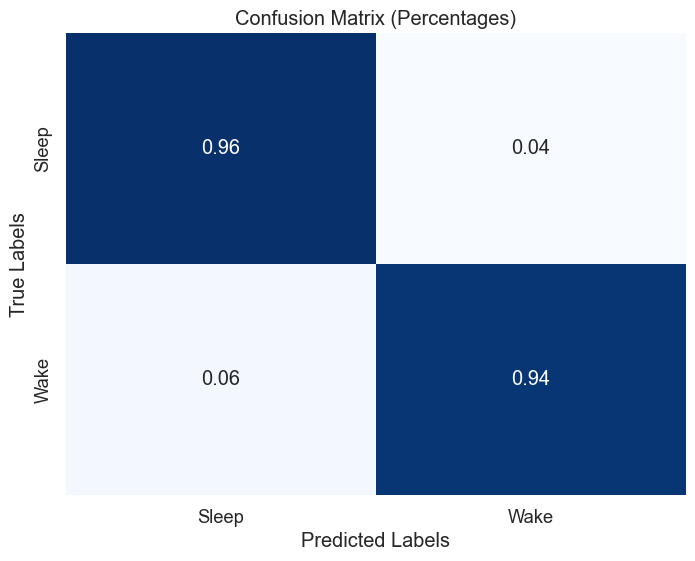

In [55]:
import seaborn as sns

# Calculate percentages
conf_matrix_percent = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]

# Set up the figure
plt.figure(figsize=(8, 6))
sns.set(font_scale=1.2)
sns.heatmap(conf_matrix_percent, annot=True, fmt=".2f", cmap="Blues", cbar=False)

# Get class labels
class_labels = ['Sleep', 'Wake']

# Set labels, title, and ticks
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix (Percentages)")
plt.xticks(np.arange(len(class_labels))+0.5, class_labels)
plt.yticks(np.arange(len(class_labels))+0.5, class_labels)

plt.show()

In [59]:
import scipy.io
list_f = scipy.io.loadmat('list_f.mat')
list_f = list_f['list_f']
list_f = list_f.reshape(-1)
# features_all_train = T_all

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Assuming you have the y_pred_prob_full array with shape (num_samples, num_classes)
# For this example, let's assume num_samples = 150 and num_classes = 5
num_samples = 150  # Change this to the actual number of samples
num_classes = 5  # Change this to the actual number of classes

# Select the first 100 samples for plotting
num_samples_to_plot = 74
y_pred_prob_to_plot = y_pred_prob_full[:num_samples_to_plot, :]

# Create a stacked bar plot for predicted probabilities
plt.figure(figsize=(10, 6))
class_labels = ['N1', 'N2', 'N3', 'R', 'W']  # Change this to your class labels
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']  # Change this to your desired colors
bottoms = np.zeros(num_samples_to_plot)

for class_idx, class_label in enumerate(class_labels):
    plt.bar(np.arange(num_samples_to_plot), y_pred_prob_to_plot[:, class_idx], bottom=bottoms, width=1, label=class_label, color=colors[class_idx], edgecolor='none')
    bottoms += y_pred_prob_to_plot[:, class_idx]

plt.xlabel("Sample Index")
plt.ylabel("Predicted Probabilities")
plt.title("Predicted Probabilities for Each Class (First 100 Samples)")
# plt.xticks(np.arange(num_samples_to_plot))
plt.legend(loc="upper left")
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from imblearn.ensemble import BalancedBaggingClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, balanced_accuracy_score

# Initialize a dictionary to store confusion matrices
class_metrics_dict30 = {}

# Loop through unique experiment identifiers
for experiment_id in range(1, 2):
    # print(experiment_id)
    # if experiment_id in [18, 33, 58]:
    #         continue
    if experiment_id in [18, 25, 33, 39, 48]:
            continue
    # Load a dataset (Iris dataset as an example)
    X = features_all_train[np.where(np.array(list_f) == experiment_id)[0], :]
    y = targets[np.where(np.array(list_f) == experiment_id)[0]]

    # Get unique class labels
    unique_classes = np.unique(y)

    # Filter classes with less than 10 samples
    filtered_classes = []
    for class_label in unique_classes:
        class_indices = np.where(y == class_label)[0]
        if len(class_indices) >= 10:
            filtered_classes.append(class_label)

    train_mask = np.isin(y, filtered_classes)
    X = X[train_mask, :]
    y = y[train_mask]

    # Initialize the base classifier with n_estimators=n_samples-1
    n_estimators = len(y) - 1
    clf = BalancedBaggingClassifier(base_estimator=None, n_estimators=n_estimators, sampling_strategy='auto', random_state=42)

    # Initialize StratifiedKFold for cross-validation
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    # Initialize arrays to store predictions and true labels
    y_pred_full = np.zeros_like(y)
    y_true_full = np.zeros_like(y)
    y_pred_prob_full = np.zeros((len(y), len(np.unique(y))))  # Array to store predicted probabilities

    # Perform cross-validation and store predictions
    for train_idx, val_idx in cv.split(X, y):
        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]
        
        # Fit the classifier on the training data
        clf.fit(X_train, y_train)
        
        # Predict on the validation data
        y_pred_val = clf.predict(X_val)
        y_pred_prob_val = clf.predict_proba(X_val)
        # Store predictions and true labels
        y_pred_full[val_idx] = y_pred_val
        y_pred_prob_full[val_idx] = y_pred_prob_val
        y_true_full[val_idx] = y_val

    conf_matrix = confusion_matrix(y_true_full, y_pred_full, labels=[1, 2, 3, 4, 5])
    class_metrics, overall_metrics = class_metrics_from_confusion_matrix(conf_matrix, y_true_full, y_pred_full)
    # class_metrics_dict30[experiment_id] = overall_metrics

    y2 = y_pred_full
    y1 = y_true_full

    # Create the first plot
    plt.plot(y1, label='true values')
    plt.xlabel('window#')
    plt.ylabel('Label')
    plt.title('Plot 1')
    plt.yticks(range(1, 6))
    plt.legend()  # Show legend

    # "Hold on" behavior: create the second plot on the same figure
    plt.plot(y2, label='prediction')
    plt.legend()  # Update the legend for the second plot

    # Display the plot
    plt.show()



# for experiment_id, class_metrics in class_metrics_dict30.items():
#     print(f"Confusion matrix for Experiment {experiment_id}:\n{class_metrics}")



(281, 5)
6


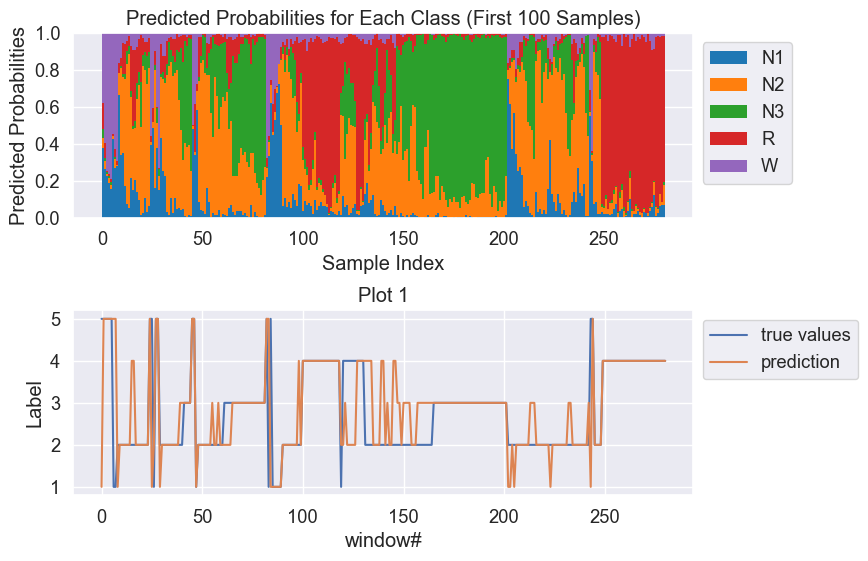

(116, 5)
34


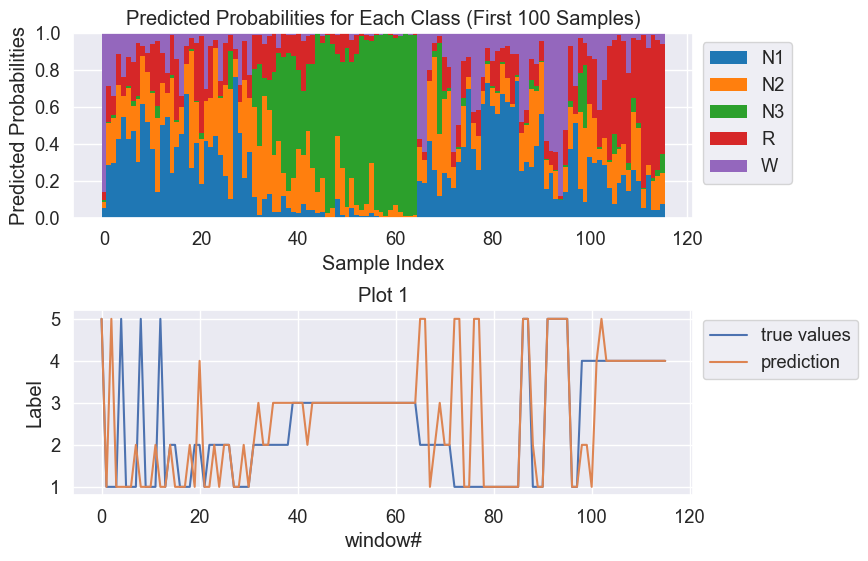

(313, 5)
36


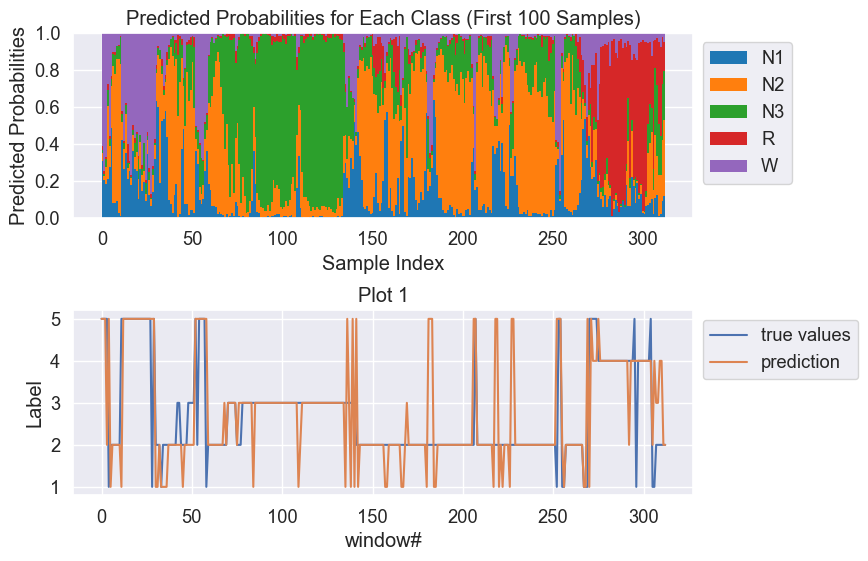

In [141]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from imblearn.ensemble import BalancedBaggingClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, balanced_accuracy_score

# Initialize a dictionary to store confusion matrices
class_metrics_dict30 = {}

# Loop through unique experiment identifiers
for experiment_id in range(1, 59):
    # print(experiment_id)
    # if experiment_id in [18, 33, 58]:
    #         continue
    if experiment_id in [18, 25, 33, 39, 48]:
            continue
    # Load a dataset (Iris dataset as an example)
    X = features_all_train[np.where(np.array(list_f) == experiment_id)[0], :]
    y = targets[np.where(np.array(list_f) == experiment_id)[0]]

    # Get unique class labels
    unique_classes = np.unique(y)

    # Filter classes with less than 10 samples
    filtered_classes = []
    for class_label in unique_classes:
        class_indices = np.where(y == class_label)[0]
        if len(class_indices) >= 10:
            filtered_classes.append(class_label)

    train_mask = np.isin(y, filtered_classes)
    X = X[train_mask, :]
    y = y[train_mask]

    # Initialize the base classifier with n_estimators=n_samples-1
    n_estimators = len(y) - 1
    clf = BalancedBaggingClassifier(base_estimator=None, n_estimators=n_estimators, sampling_strategy='auto', random_state=42)

    # Initialize StratifiedKFold for cross-validation
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    # Initialize arrays to store predictions and true labels
    y_pred_full = np.zeros_like(y)
    y_true_full = np.zeros_like(y)
    y_pred_prob_full = np.zeros((len(y), len(np.unique(y))))  # Array to store predicted probabilities

    if len(np.unique(y)) == 5 :
        # Perform cross-validation and store predictions
        for train_idx, val_idx in cv.split(X, y):
            X_train, X_val = X[train_idx], X[val_idx]
            y_train, y_val = y[train_idx], y[val_idx]
            
            # Fit the classifier on the training data
            clf.fit(X_train, y_train)
            
            # Predict on the validation data
            y_pred_val = clf.predict(X_val)
            y_pred_prob_val = clf.predict_proba(X_val)

            # Store predictions and true labels
            y_pred_full[val_idx] = y_pred_val
            y_true_full[val_idx] = y_val
            y_pred_prob_full[val_idx] = y_pred_prob_val
        

        # import numpy as np
        # import matplotlib.pyplot as plt

        # Assuming you have the y_pred_prob_full array with shape (num_samples, num_classes)
        # For this example, let's assume num_samples = 150 and num_classes = 5
        num_samples = 150  # Change this to the actual number of samples
        num_classes = 5  # Change this to the actual number of classes

        # Select the first 100 samples for plotting
        num_samples_to_plot = len(y)
        y_pred_prob_to_plot = y_pred_prob_full[:num_samples_to_plot, :]

        # Create a stacked bar plot for predicted probabilities
        plt.figure(figsize=(8, 6))
        plt.subplot(2, 1, 1)
        class_labels = ['N1', 'N2', 'N3', 'R', 'W']  # Change this to your class labels
        colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']  # Change this to your desired colors
        bottoms = np.zeros(num_samples_to_plot)

        print(y_pred_prob_to_plot.shape)
        print(experiment_id)
        for class_idx, class_label in enumerate(class_labels):
            plt.bar(np.arange(num_samples_to_plot), y_pred_prob_to_plot[:, class_idx], bottom=bottoms, width=1, label=class_label, color=colors[class_idx], edgecolor='none')
            bottoms += y_pred_prob_to_plot[:, class_idx]

        plt.xlabel("Sample Index")
        plt.ylabel("Predicted Probabilities")
        plt.title("Predicted Probabilities for Each Class (First 100 Samples)")
        # plt.xticks(np.arange(num_samples_to_plot))
        plt.legend(loc="upper left")
        plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
        # plt.show()

        y2 = y_pred_full
        y1 = y_true_full
        # plt.figure(figsize=(10, 6))
        plt.subplot(2, 1, 2)
        # Create the first plot
        plt.plot(y1, label='true values')
        plt.xlabel('window#')
        plt.ylabel('Label')
        plt.title('Plot 1')
        plt.yticks(range(1, 6))
        plt.legend()  # Show legend

        # "Hold on" behavior: create the second plot on the same figure
        plt.plot(y2, label='prediction')
        plt.legend()  # Update the legend for the second plot
        
        plt.subplots_adjust(hspace=0.5)
        plt.legend(loc='upper left', bbox_to_anchor=(1, 1))

        # Display the plot
        plt.show()




        

    # conf_matrix = confusion_matrix(y_true_full, y_pred_full, labels=[1, 2, 3, 4, 5])
    # class_metrics, overall_metrics = class_metrics_from_confusion_matrix(conf_matrix, y_true_full, y_pred_full)
    # class_metrics_dict30[experiment_id] = overall_metrics

    # y2 = y_pred_full
    # y1 = y_true_full

    # # Create the first plot
    # plt.plot(y1, label='true values')
    # plt.xlabel('window#')
    # plt.ylabel('Label')
    # plt.title('Plot 1')
    # plt.yticks(range(1, 6))
    # plt.legend()  # Show legend

    # # "Hold on" behavior: create the second plot on the same figure
    # plt.plot(y2, label='prediction')
    # plt.legend()  # Update the legend for the second plot

    # # Display the plot
    # plt.show()


# for experiment_id, class_metrics in class_metrics_dict30.items():
#     print(f"Confusion matrix for Experiment {experiment_id}:\n{class_metrics}")